# Backtesting de Trading Automático: Enfoque Heurístico (Últimos 3 Años)

Este notebook presenta un ejemplo práctico de cómo diseñar, simular y evaluar una **estrategia de trading heurística** utilizando Python, Pandas y Matplotlib.

### Estrategia Utilizada
Combinamos seguimiento de tendencia con un indicador de impulso:
1. **Tendencia**: Cruce de Medias Móviles Exponenciales (EMA de 12 y 50 días).
2. **Momento**: Índice de Fuerza Relativa (RSI de 14 días) para confirmar la fuerza del movimiento y evitar sobrecompra.

### Datos de Entrada
Utilizamos el archivo de datos reales históricos para la acción de **Google LLC (GOOGL)**, filtrado automáticamente para obtener los **últimos 3 años** disponibles en el dataset:
`~/.cache/kagglehub/datasets/borismarjanovic/price-volume-data-for-all-us-stocks-etfs/versions/3/Data/Stocks/googl.us.txt`

In [1]:
import os

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## 1. Carga de Datos Históricos Reales (Últimos 3 Años)
Cargamos los datos reales y aplicamos un filtro relativo para obtener exactamente los últimos 3 años en base al registro más reciente del dataset.

In [2]:
# Download data
path = kagglehub.dataset_download("borismarjanovic/price-volume-data-for-all-us-stocks-etfs")

print("Path to dataset files:", path)

Path to dataset files: /Users/lgutierrez/.cache/kagglehub/datasets/borismarjanovic/price-volume-data-for-all-us-stocks-etfs/versions/3


In [3]:
def load_real_data(
    file_path="~/.cache/kagglehub/datasets/borismarjanovic/price-volume-data-for-all-us-stocks-etfs/versions/3/Data/Stocks/googl.us.txt",
):
    """
    Carga datos históricos reales de precios de acciones en formato CSV/TXT.
    Filtra para retornar únicamente los últimos 3 años de datos disponibles.
    """
    expanded_path = os.path.expanduser(file_path)
    if not os.path.exists(expanded_path):
        raise FileNotFoundError(f"No se encontró el archivo de datos reales en {expanded_path}")

    df = pd.read_csv(expanded_path)
    df["Date"] = pd.to_datetime(df["Date"])
    df.set_index("Date", inplace=True)
    df.columns = [col.lower() for col in df.columns]

    # Filtrar últimos 3 años de datos en base al último registro disponible
    max_date = df.index.max()
    start_date = max_date - pd.DateOffset(years=3)
    df = df[df.index >= start_date]

    return df

## 2. Cálculo de Indicadores Técnicos
Calculamos las dos Medias Móviles Exponenciales (EMA de 12 y 50 días) y el Índice de Fuerza Relativa (RSI de 14 días).

In [4]:
def calculate_indicators(df):
    """
    Calcula las EMAs (12 y 50 periodos) y el RSI de 14 periodos.
    """
    df["ema_fast"] = df["close"].ewm(span=12, adjust=False).mean()
    df["ema_slow"] = df["close"].ewm(span=50, adjust=False).mean()

    delta = df["close"].diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()

    rs = gain / (loss + 1e-9)
    df["rsi"] = 100 - (100 / (1 + rs))
    return df

## 3. Lógica del Algoritmo Heurístico
Implementamos las reglas de decisión de compra y venta:

In [5]:
def run_heuristic_strategy(df):
    """
    Ejecuta la estrategia y guarda la posición en el mercado día a día (0 o 1).
    """
    positions = []
    position = 0  # 0 = Fuera, 1 = Dentro
    trades = []
    entry_price = 0.0
    entry_date = None

    for i in range(len(df)):
        if i < 50:
            positions.append(0)
            continue

        current_close = df["close"].iloc[i]
        current_ema_fast = df["ema_fast"].iloc[i]
        current_ema_slow = df["ema_slow"].iloc[i]
        prev_ema_fast = df["ema_fast"].iloc[i - 1]
        prev_ema_slow = df["ema_slow"].iloc[i - 1]
        current_rsi = df["rsi"].iloc[i]

        crossed_above = (prev_ema_fast <= prev_ema_slow) and (current_ema_fast > current_ema_slow)
        crossed_below = (prev_ema_fast >= prev_ema_slow) and (current_ema_fast < current_ema_slow)

        # Lógica heurística
        if position == 0:
            if crossed_above and (50 < current_rsi < 70):
                position = 1
                entry_price = current_close
                entry_date = df.index[i]
        elif position == 1:
            # Salida por cruce bajista o sobrecompra extrema
            if crossed_below or (current_rsi > 85):
                position = 0
                pct_return = (current_close - entry_price) / entry_price
                trades.append(
                    {
                        "entry_date": entry_date,
                        "exit_date": df.index[i],
                        "entry_price": entry_price,
                        "exit_price": current_close,
                        "return": pct_return,
                    }
                )

        positions.append(position)

    df["position"] = positions
    return df, trades

## 4. Evaluación de Rendimiento (Métricas de Backtesting)
Calculamos métricas cuantitativas clave penalizando cada operación con comisiones del $0.1\%$ para simular condiciones reales.

In [6]:
def evaluate_performance(df, trades, comision=0.001):
    """
    Calcula y muestra métricas cuantitativas del backtest.
    """
    # Retornos diarios
    df["market_return"] = df["close"].pct_change()
    df["strategy_return"] = df["position"].shift(1) * df["market_return"]

    # Penalizar comisiones al cambiar de posición
    position_changes = df["position"].diff().abs().fillna(0)
    df["strategy_return"] = df["strategy_return"] - (position_changes * comision)

    # Retornos acumulados
    df["cum_market_return"] = (1 + df["market_return"].fillna(0)).cumprod() - 1
    df["cum_strategy_return"] = (1 + df["strategy_return"].fillna(0)).cumprod() - 1

    total_market_ret = df["cum_market_return"].iloc[-1]
    total_strat_ret = df["cum_strategy_return"].iloc[-1]

    # Sharpe Ratio Anualizado
    daily_std = df["strategy_return"].std()
    avg_daily_return = df["strategy_return"].mean()
    sharpe_ratio = (avg_daily_return / daily_std) * np.sqrt(365) if daily_std > 0 else 0

    # Máximo Drawdown
    cum_wealth = (1 + df["strategy_return"].fillna(0)).cumprod()
    running_max = cum_wealth.cummax()
    drawdown = (cum_wealth - running_max) / running_max
    max_drawdown = drawdown.min()

    num_trades = len(trades)
    if num_trades > 0:
        winning_trades = [t for t in trades if t["return"] > 0]
        win_rate = len(winning_trades) / num_trades
        avg_trade_ret = np.mean([t["return"] for t in trades])
    else:
        win_rate = 0.0
        avg_trade_ret = 0.0

    print("==================================================")
    print("       RESULTADOS DEL BACKTESTING (EVALUACIÓN)    ")
    print("==================================================")
    print(
        f"Rango de Fechas Evaluadas:             {df.index.min().strftime('%Y-%m-%d')} a {df.index.max().strftime('%Y-%m-%d')}"
    )
    print(f"Retorno Acumulado Activo (Buy & Hold): {total_market_ret * 100:.2f}%")
    print(f"Retorno Acumulado Estrategia:          {total_strat_ret * 100:.2f}%")
    print(f"Sharpe Ratio Anualizado:               {sharpe_ratio:.2f}")
    print(f"Máximo Drawdown (Peor Caída):          {max_drawdown * 100:.2f}%")
    print(f"Número total de operaciones realizadas: {num_trades}")
    if num_trades > 0:
        print(f"Tasa de Acierto (Win Rate):            {win_rate * 100:.2f}%")
        print(f"Retorno Promedio por Operación:         {avg_trade_ret * 100:.2f}%")
    print("==================================================")

## 5. Visualización del Rendimiento
Graficamos la evolución del precio y los retornos acumulados directamente en el notebook.

In [7]:
def plot_performance_inline(df, trades):
    """
    Grafica y muestra la evolución del precio y el rendimiento de la estrategia.
    """
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=False)

    # Subplot 1: Últimos 300 días de la acción con flechas de trade
    plot_len = min(len(df), 300)
    df_slice = df.iloc[-plot_len:]

    ax1.plot(
        df_slice.index,
        df_slice["close"],
        label="Precio Cierre (Close)",
        color="#1f77b4",
        linewidth=1.5,
    )
    ax1.plot(
        df_slice.index,
        df_slice["ema_fast"],
        label="EMA Rápida (12d)",
        color="#ff7f0e",
        linestyle="--",
        linewidth=1.2,
    )
    ax1.plot(
        df_slice.index,
        df_slice["ema_slow"],
        label="EMA Lenta (50d)",
        color="#2ca02c",
        linestyle="--",
        linewidth=1.2,
    )

    slice_start_date = df_slice.index[0]
    for trade in trades:
        if trade["entry_date"] >= slice_start_date:
            ax1.scatter(
                trade["entry_date"],
                trade["entry_price"],
                color="green",
                marker="^",
                s=120,
                label="Compra" if "Compra" not in ax1.get_legend_handles_labels()[1] else "",
                zorder=5,
            )
            ax1.scatter(
                trade["exit_date"],
                trade["exit_price"],
                color="red",
                marker="v",
                s=120,
                label="Venta" if "Venta" not in ax1.get_legend_handles_labels()[1] else "",
                zorder=5,
            )

    ax1.set_title(f"Precio de Cierre, EMAs y Señales (Últimos {plot_len} Días)")
    ax1.set_ylabel("Precio ($)")
    ax1.grid(True, linestyle=":", alpha=0.6)
    ax1.legend(loc="upper left")

    # Subplot 2: Retornos Acumulados Completos (Últimos 3 años)
    ax2.plot(
        df_slice.index,
        df_slice["cum_market_return"] * 100,
        label="Mercado (Buy & Hold)",
        color="#d62728",
        linewidth=1.5,
    )
    ax2.plot(
        df_slice.index,
        df_slice["cum_strategy_return"] * 100,
        label="Estrategia Heurística",
        color="#2ca02c",
        linewidth=1.5,
    )

    ax2.set_title(f"Retornos Acumulados (Estrategia vs Mercado - Últimos {plot_len} Días)")
    ax2.set_ylabel("Retorno (%)")
    ax2.set_xlabel("Fecha")
    ax2.grid(True, linestyle=":", alpha=0.6)
    ax2.legend(loc="upper left")

    plt.tight_layout()
    plt.show()

## 6. Ejecución del Backtesting con Datos Reales (3 Años)
Cargamos la serie real de GOOGL y ejecutamos la estrategia heurística.

       RESULTADOS DEL BACKTESTING (EVALUACIÓN)    
Rango de Fechas Evaluadas:             2014-11-10 a 2017-11-10
Retorno Acumulado Activo (Buy & Hold): 87.05%
Retorno Acumulado Estrategia:          7.56%
Sharpe Ratio Anualizado:               0.30
Máximo Drawdown (Peor Caída):          -18.14%
Número total de operaciones realizadas: 8
Tasa de Acierto (Win Rate):            25.00%
Retorno Promedio por Operación:         0.51%


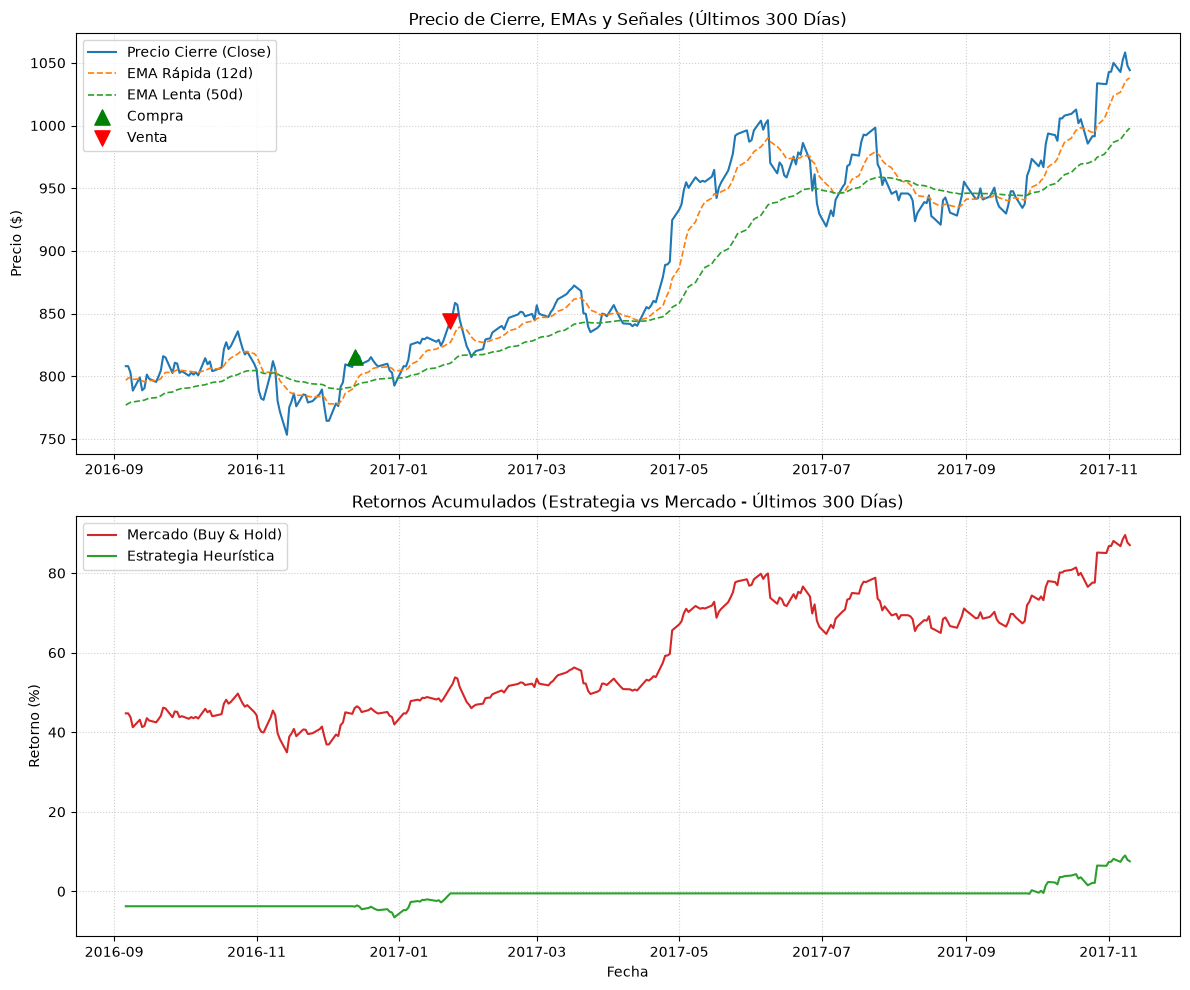

In [8]:
# Cargar los datos de GOOGL
df = load_real_data()
df = calculate_indicators(df)
df, trades = run_heuristic_strategy(df)

# Evaluar métricas financieras
evaluate_performance(df, trades)

# Dibujar gráficos inline
plot_performance_inline(df, trades)